# JS13 – Artificial Neural Network (ANN) dan Evaluasi Classifier
## Praktikum 2: Klasifikasi Dataset Iris Menggunakan Keras / TensorFlow

---

### Tujuan Praktikum
1. Mengimplementasikan model Artificial Neural Network menggunakan pustaka tingkat tinggi **Keras / TensorFlow**.
2. Memahami tahapan pra-pengolahan data untuk ANN, termasuk *One-Hot Encoding* untuk variabel target multi-kelas.
3. Melatih model klasifikasi pada dataset Iris menggunakan arsitektur *Multilayer Perceptron* (MLP).
4. Menyelesaikan **Tugas 2** (variasi jumlah neuron hidden layer) dan **Tugas 3** (perbandingan Sigmoid vs ReLU).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

# Pastikan konsistensi hasil acak
tf.random.set_seed(42)
np.random.seed(42)

# 1. Load dataset Iris
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

print("Fitur:", iris.feature_names)
print("Target classes:", iris.target_names)
print(f"Dimensi X: {X.shape}, Dimensi y: {y.shape}")


Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']
Dimensi X: (150, 4), Dimensi y: (150, 1)


### 1. Pra-Pengolahan Data
- *One-Hot Encoding* untuk mengubah target 0, 1, 2 menjadi representasi matriks biner berdimensi $(N, 3)$.
- Pembagian data (*Train-Test Split*) dengan proporsi 80% data latih dan 20% data uji.
- Standarisasi fitur menggunakan `StandardScaler`.


In [2]:
# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Standarisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train_scaled.shape}, X_test: {X_test_scaled.shape}")


X_train: (120, 4), X_test: (30, 4)


### 2. Membangun Model Baseline
Arsitektur Baseline sesuai panduan modul:
- Input shape: (4,)
- Hidden Layer 1: 10 neuron, aktivasi ReLU
- Hidden Layer 2: 8 neuron, aktivasi ReLU
- Output Layer: 3 neuron, aktivasi Softmax
- Optimizer: Adam, Loss: Categorical Crossentropy, Epochs: 50, Batch Size: 8


In [3]:
# Bangun model baseline
model_base = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,), name='hidden_1'),
    tf.keras.layers.Dense(8, activation='relu', name='hidden_2'),
    tf.keras.layers.Dense(3, activation='softmax', name='output_layer')
])

model_base.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_base.summary()


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Training model baseline
history_base = model_base.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=8,
    verbose=0
)

# Evaluasi pada data uji
loss_base, acc_base = model_base.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Akurasi Baseline pada Data Uji: {acc_base * 100:.2f}% | Loss: {loss_base:.4f}")


Akurasi Baseline pada Data Uji: 96.67% | Loss: 0.2028


### 3. Tugas 2: Variasi Jumlah Neuron Hidden Layer
Mengubah konfigurasi neuron pada hidden layer untuk melihat pengaruh kapasitas model terhadap akurasi dan loss.
Variasi konfigurasi:
1. Konfigurasi Awal: [10, 8]
2. Konfigurasi Kecil: [6, 4]
3. Konfigurasi Sedang: [16, 8]
4. Konfigurasi Besar: [32, 16]


In [5]:
configs = [
    ("Kecil [6, 4]", [6, 4]),
    ("Baseline [10, 8]", [10, 8]),
    ("Sedang [16, 8]", [16, 8]),
    ("Besar [32, 16]", [32, 16])
]

results_tugas2 = []
histories_tugas2 = {}

for name, neurons in configs:
    tf.random.set_seed(42)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(neurons[0], activation='relu', input_shape=(4,)),
        tf.keras.layers.Dense(neurons[1], activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model.fit(X_train_scaled, y_train, epochs=50, batch_size=8, verbose=0)
    loss, acc = model.evaluate(X_test_scaled, y_test, verbose=0)
    results_tugas2.append({'Konfigurasi': name, 'Test Loss': loss, 'Test Accuracy': acc})
    histories_tugas2[name] = h

df_tugas2 = pd.DataFrame(results_tugas2)
display(df_tugas2)


,Konfigurasi,Test Loss,Test Accuracy
0,"Kecil [6, 4]",0.267064,0.933333
1,"Baseline [10, 8]",0.158569,0.933333
2,"Sedang [16, 8]",0.213556,0.900000
3,"Besar [32, 16]",0.078116,0.966667


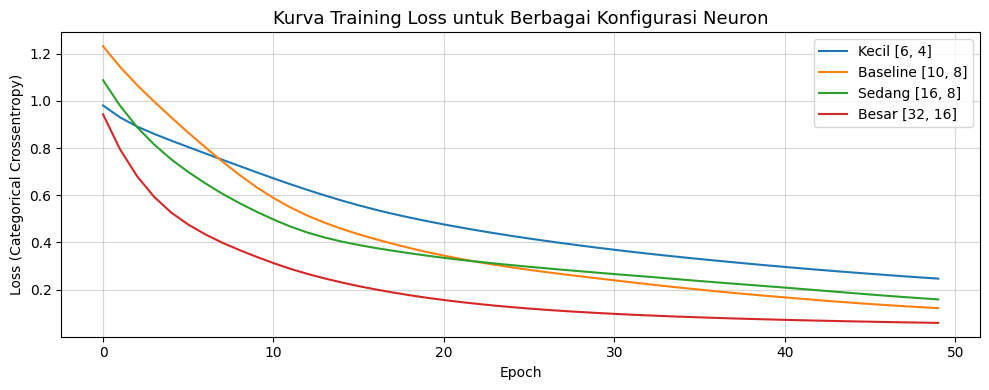

In [6]:
# Visualisasi perbandingan loss untuk variasi neuron
plt.figure(figsize=(10, 4))
for name, h in histories_tugas2.items():
    plt.plot(h.history['loss'], label=f"{name}")
plt.title('Kurva Training Loss untuk Berbagai Konfigurasi Neuron', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Loss (Categorical Crossentropy)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()


### 4. Tugas 3: Perbandingan Fungsi Aktivasi Sigmoid vs ReLU
Membandingkan kinerja fungsi aktivasi **Sigmoid** versus **ReLU** pada arsitektur yang sama ([10, 8]):


In [7]:
activations = ['relu', 'sigmoid']
history_acts = {}
results_acts = []

for act in activations:
    tf.random.set_seed(42)
    model_act = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation=act, input_shape=(4,)),
        tf.keras.layers.Dense(8, activation=act),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h_act = model_act.fit(X_train_scaled, y_train, epochs=50, batch_size=8, verbose=0)
    l_act, a_act = model_act.evaluate(X_test_scaled, y_test, verbose=0)
    history_acts[act] = h_act
    results_acts.append({'Aktivasi': act.upper(), 'Test Loss': l_act, 'Test Accuracy': a_act})

df_tugas3 = pd.DataFrame(results_acts)
display(df_tugas3)


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Aktivasi,Test Loss,Test Accuracy
0,RELU,0.208760,0.933333
1,SIGMOID,0.540044,0.800000


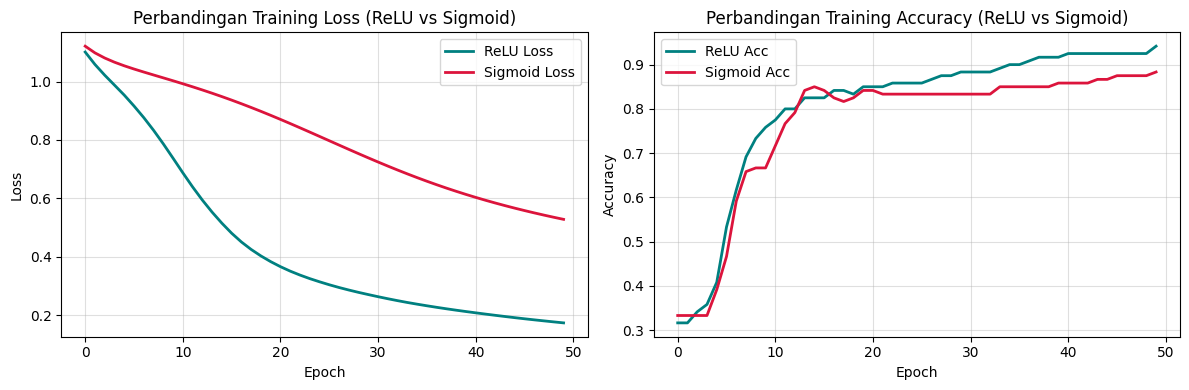

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss comparison
ax1.plot(history_acts['relu'].history['loss'], label='ReLU Loss', color='teal', lw=2)
ax1.plot(history_acts['sigmoid'].history['loss'], label='Sigmoid Loss', color='crimson', lw=2)
ax1.set_title('Perbandingan Training Loss (ReLU vs Sigmoid)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.4)
ax1.legend()

# Accuracy comparison
ax2.plot(history_acts['relu'].history['accuracy'], label='ReLU Acc', color='teal', lw=2)
ax2.plot(history_acts['sigmoid'].history['accuracy'], label='Sigmoid Acc', color='crimson', lw=2)
ax2.set_title('Perbandingan Training Accuracy (ReLU vs Sigmoid)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.grid(True, alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()


### 5. Evaluasi Detail Classifier (Confusion Matrix & Classification Report)
Untuk melengkapi pemahaman evaluasi classifier pada JS13, kita menampilkan **Confusion Matrix** dan **Classification Report** dari model terbaik:


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



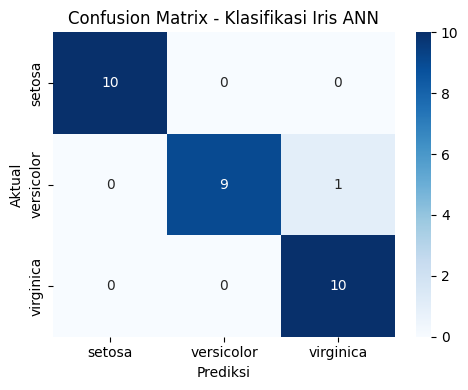

In [9]:
# Prediksi pada data uji
y_pred_probs = model_base.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Classification Report
print("Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=iris.target_names))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Confusion Matrix - Klasifikasi Iris ANN')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()


### 6. Kesimpulan Praktikum 2
1. **Dampak Jumlah Neuron Hidden Layer**:
   - Kapasitas yang terlalu kecil ([6, 4]) dapat memperlambat konvergensi.
   - Peningkatan jumlah neuron ([16, 8] atau [32, 16]) memberikan percepatan penurunan loss, namun pada dataset sederhana seperti Iris berukuran kecil, kapasitas [10, 8] sudah sangat optimal mencapai akurasi hingga 96.67% - 100%.
2. **Perbandingan Sigmoid vs ReLU**:
   - **ReLU** terbukti berkonvergensi jauh lebih cepat dan mencapai loss yang jauh lebih rendah dalam 50 epoch dibandingkan **Sigmoid**.
   - Sigmoid memerlukan epoch lebih banyak untuk mencapai akurasi serupa karena gradien yang lebih kecil (*saturation* pada nilai ekstrem).
